# R7 - Auditoría estadística de B0-B3

**Objetivo.** Reproducir, solo con las predicciones de validation ya guardadas, la comparación del Average Precision (AP) de B1, B2 y B3 frente a la línea base B0, separando dos fuentes de incertidumbre distintas:

1. **Variabilidad entre semillas** (42, 43 y 44): cuánto cambia el resultado al repetir el entrenamiento.
2. **Remuestreo de imágenes** (bootstrap): cuánto cambiaría el ΔAP si el conjunto de validation fuera otra muestra de imágenes, manteniendo fijos los modelos ya entrenados.

**Qué no hace.** No entrena, no usa test, no modifica B0-B3 ni sus predicciones, y no elige umbrales. Todo se calcula sobre las 200 imágenes de validation, de las cuales 22 son positivas operacionales: la etiqueta positiva (`y_true = 1`) agrupa las categorías originales 6 y 7, y no se analiza cada categoría por separado.

| | Origen (solo lectura) |
|---|---|
| B0 | `results/classification/r4_benchmark/convnext_tiny/A/seed_{42,43,44}/` |
| B1 | `results/classification/r7_optimizacion/early_stopping/seed_{42,43,44}/` |
| B2 | `results/classification/r7_optimizacion/class_weights/seed_{42,43,44}/` |
| B3 | `results/classification/r7_optimizacion/focal_loss/seed_{42,43,44}/` |

Cada carpeta aporta `val_predictions_best_auc.csv` (probabilidades del checkpoint de máximo `val_roc_auc`) y `validation_metrics.json`.

## 1. Configuración

In [1]:
from pathlib import Path
import json

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from sklearn.metrics import average_precision_score


def locate_project_root() -> Path:
    current_dir = Path.cwd().resolve()

    for candidate in [current_dir, *current_dir.parents]:
        if (candidate / "src").exists() and (candidate / "data").exists():
            return candidate

    raise FileNotFoundError("No se pudo localizar la raíz del proyecto.")


PROJECT_ROOT = locate_project_root()

SEEDS = [42, 43, 44]
N_BOOT = 2000
BOOT_SEED = 20260101  # semilla fija del remuestreo
CI_LEVEL = 95

CLASSIFICATION_DIR = PROJECT_ROOT / "results" / "classification"
R7_DIR = CLASSIFICATION_DIR / "r7_optimizacion"
CONFIG_DIRS = {
    "B0": CLASSIFICATION_DIR / "r4_benchmark" / "convnext_tiny" / "A",
    "B1": R7_DIR / "early_stopping",
    "B2": R7_DIR / "class_weights",
    "B3": R7_DIR / "focal_loss",
}
CONFIGS = list(CONFIG_DIRS)  # B0 es la referencia
COMPARED = CONFIGS[1:]
OUT_DIR = R7_DIR / "analisis_estadistico"  # salidas de este notebook; no toca B0-B3

# Valores de referencia de una exploración previa: se contrastan, no se usan como resultado
REFERENCE_DELTA = {"B1": 0.0186, "B2": 0.0701, "B3": 0.0041}
REFERENCE_B2_CI = (0.0061, 0.1390)

## 2. Integridad de los 12 archivos

Cada archivo se indexa por `image_id` y se ordena por ese identificador, de modo que el análisis no depende del orden de las filas. Se comprueba, para cada uno: columnas requeridas, ausencia de valores faltantes, probabilidades en [0, 1], `image_id` únicos, y coincidencia exacta del conjunto de `image_id` y de `y_true` con B0 / semilla 42.

In [2]:
REQUIRED_COLUMNS = ["image_id", "y_true", "probability_malignant"]


def read_predictions(path: Path) -> pd.DataFrame:
    df = pd.read_csv(path)
    missing_columns = set(REQUIRED_COLUMNS) - set(df.columns)
    assert not missing_columns, f"{path}: faltan columnas {sorted(missing_columns)}"
    assert not df[REQUIRED_COLUMNS].isna().any().any(), f"{path}: valores faltantes"
    assert df["image_id"].is_unique, f"{path}: image_id repetidos"
    assert df["probability_malignant"].between(0, 1).all(), f"{path}: probabilidades fuera de [0, 1]"
    assert set(df["y_true"]) <= {0, 1}, f"{path}: y_true no binario"
    return df


RAW = {
    (config, seed): read_predictions(directory / f"seed_{seed}" / "val_predictions_best_auc.csv")
    for config, directory in CONFIG_DIRS.items()
    for seed in SEEDS
}
PRED = {key: df.set_index("image_id").sort_index() for key, df in RAW.items()}

reference = PRED[("B0", SEEDS[0])]
reference_raw_order = RAW[("B0", SEEDS[0])]["image_id"].to_numpy()

integrity = []
for (config, seed), df in PRED.items():
    same_ids = df.index.equals(reference.index)
    same_labels = same_ids and np.array_equal(df["y_true"].to_numpy(), reference["y_true"].to_numpy())
    integrity.append(
        {
            "config": config,
            "seed": seed,
            "n": len(df),
            "positivas operacionales": int(df["y_true"].sum()),
            "image_id únicos": df.index.is_unique,
            "mismo conjunto de image_id": same_ids,
            "mismo y_true por image_id": same_labels,
            "mismo orden de filas que B0/42": bool(np.array_equal(RAW[(config, seed)]["image_id"].to_numpy(), reference_raw_order)),
            "época": int(RAW[(config, seed)]["epoch"].iloc[0]) if "epoch" in RAW[(config, seed)] else None,
        }
    )
integrity = pd.DataFrame(integrity)
display(integrity)

assert len(PRED) == len(CONFIGS) * len(SEEDS) == 12
assert integrity["image_id únicos"].all()
assert integrity["mismo conjunto de image_id"].all()
assert integrity["mismo y_true por image_id"].all()
print(f"Integridad correcta: 12 archivos, {len(reference)} imágenes ({int(reference['y_true'].sum())} positivas operacionales) idénticas en todos.")

# Arreglo común, alineado por image_id: P[config, seed, imagen]
IMAGE_IDS = reference.index.to_numpy()
y = reference["y_true"].to_numpy()
P = np.stack([[PRED[(config, seed)]["probability_malignant"].to_numpy() for seed in SEEDS] for config in CONFIGS])
print("P:", P.shape, "(config, semilla, imagen)")

,config,seed,n,positivas operacionales,image_id únicos,mismo conjunto de image_id,mismo y_true por image_id,mismo orden de filas que B0/42,época
0,B0,42,200,22,True,True,True,True,8
1,B0,43,200,22,True,True,True,True,7
2,B0,44,200,22,True,True,True,True,7
3,B1,42,200,22,True,True,True,True,23
4,B1,43,200,22,True,True,True,True,14
5,B1,44,200,22,True,True,True,True,18
6,B2,42,200,22,True,True,True,True,7
7,B2,43,200,22,True,True,True,True,7
8,B2,44,200,22,True,True,True,True,8
9,B3,42,200,22,True,True,True,True,10


Integridad correcta: 12 archivos, 200 imágenes (22 positivas operacionales) idénticas en todos.
P: (4, 3, 200) (config, semilla, imagen)


## 3. Average Precision por configuración y semilla

El AP se recalcula con `sklearn.metrics.average_precision_score` a partir de las probabilidades y se contrasta con el `average_precision` de `validation_metrics.json`.

In [3]:
AP = np.array([[average_precision_score(y, P[c, s]) for s in range(len(SEEDS))] for c in range(len(CONFIGS))])

saved_ap = np.array(
    [
        [json.loads((CONFIG_DIRS[config] / f"seed_{seed}" / "validation_metrics.json").read_text(encoding="utf-8"))["average_precision"] for seed in SEEDS]
        for config in CONFIGS
    ]
)

check = pd.DataFrame(
    [
        {"config": config, "seed": seed, "AP recalculado": AP[c, s], "AP guardado": saved_ap[c, s], "diferencia absoluta": abs(AP[c, s] - saved_ap[c, s])}
        for c, config in enumerate(CONFIGS)
        for s, seed in enumerate(SEEDS)
    ]
)
display(check.round({"AP recalculado": 4, "AP guardado": 4}))
max_diff = check["diferencia absoluta"].max()
assert max_diff < 1e-8, f"El AP recalculado no coincide con el guardado (máx. {max_diff:.2e})"
print(f"AP recalculado = AP guardado en las 12 corridas (diferencia máxima {max_diff:.1e}).")

ap_mean = AP.mean(axis=1)
ap_sd = AP.std(axis=1, ddof=1)  # desviación estándar muestral entre semillas
display(pd.DataFrame({"AP medio": ap_mean, "SD entre semillas (n-1)": ap_sd}, index=CONFIGS).round(4))

,config,seed,AP recalculado,AP guardado,diferencia absoluta
0,B0,42,0.5898,0.5898,0.0
1,B0,43,0.5295,0.5295,0.0
2,B0,44,0.5046,0.5046,0.0
3,B1,42,0.6115,0.6115,0.0
4,B1,43,0.4597,0.4597,0.0
5,B1,44,0.6083,0.6083,0.0
6,B2,42,0.6050,0.6050,0.0
7,B2,43,0.6501,0.6501,0.0
8,B2,44,0.5790,0.5790,0.0
9,B3,42,0.4606,0.4606,0.0


AP recalculado = AP guardado en las 12 corridas (diferencia máxima 0.0e+00).


,AP medio,SD entre semillas (n-1)
B0,0.5413,0.0438
B1,0.5599,0.0867
B2,0.6114,0.0359
B3,0.5454,0.0755


## 4. ΔAP frente a B0 por semilla (variabilidad entre semillas)

Se compara cada semilla con la misma semilla de B0. Aquí no interviene ningún remuestreo: es la variación observada al repetir el entrenamiento, con solo tres repeticiones.

In [4]:
DELTA_SEED = AP[1:] - AP[0]  # (config comparada, semilla)
delta_mean = DELTA_SEED.mean(axis=1)
delta_sd = DELTA_SEED.std(axis=1, ddof=1)

by_seed = pd.DataFrame(DELTA_SEED, index=COMPARED, columns=[f"ΔAP semilla {seed}" for seed in SEEDS])
by_seed["ΔAP medio"] = delta_mean
by_seed["SD entre semillas (n-1)"] = delta_sd
by_seed["semillas con ΔAP > 0"] = (DELTA_SEED > 0).sum(axis=1)
display(by_seed.round(4))

,ΔAP semilla 42,ΔAP semilla 43,ΔAP semilla 44,ΔAP medio,SD entre semillas (n-1),semillas con ΔAP > 0
B1,0.0217,-0.0698,0.1038,0.0186,0.0868,2
B2,0.0153,0.1205,0.0744,0.0701,0.0528,3
B3,-0.1292,0.0411,0.1005,0.0041,0.1192,2


## 5. Bootstrap pareado y estratificado (remuestreo de imágenes)

Procedimiento, con semilla fija (`BOOT_SEED`) y `N_BOOT = 2000` réplicas:

- En cada réplica se remuestrean con reemplazo las imágenes **dentro de cada clase** (22 positivas operacionales y 178 negativas), de modo que cada réplica conserva la proporción de clases.
- **Los mismos índices se aplican a las 4 configuraciones y a las 3 semillas** (pareado por imagen): la diferencia entre B0 y Bx no se contamina con ruido de muestreo distinto.
- En cada réplica se calcula el AP de las 12 corridas, el ΔAP de cada semilla frente a B0 y la **media de los tres ΔAP**.
- El IC del 95 % es el percentil 2.5-97.5 de esas medias.

Este intervalo mide la incertidumbre por **qué imágenes** componen validation, condicionada a los tres modelos entrenados por configuración. No incorpora la variabilidad de entrenamiento, que es la de la sección 4.

In [5]:
rng = np.random.default_rng(BOOT_SEED)
positives = np.flatnonzero(y == 1)
negatives = np.flatnonzero(y == 0)

boot_ap = np.empty((N_BOOT, len(CONFIGS), len(SEEDS)))
for b in range(N_BOOT):
    idx = np.concatenate([rng.choice(positives, positives.size), rng.choice(negatives, negatives.size)])
    yb = y[idx]
    for c in range(len(CONFIGS)):
        for s in range(len(SEEDS)):
            boot_ap[b, c, s] = average_precision_score(yb, P[c, s, idx])

boot_delta_seed = boot_ap[:, 1:, :] - boot_ap[:, [0], :]  # (réplica, config comparada, semilla)
boot_delta = boot_delta_seed.mean(axis=2)  # media de los tres ΔAP por réplica

lo, hi = (100 - CI_LEVEL) / 2, 100 - (100 - CI_LEVEL) / 2
ci_low, ci_high = np.percentile(boot_delta, [lo, hi], axis=0)
boot_se = boot_delta.std(axis=0, ddof=1)
share_positive = (boot_delta > 0).mean(axis=0)
ci_seed_low, ci_seed_high = np.percentile(boot_delta_seed, [lo, hi], axis=0)  # (config, semilla)

assert np.isfinite(boot_ap).all()
print(f"{N_BOOT} réplicas; cada una con {positives.size} positivas operacionales y {negatives.size} negativas remuestreadas.")

display(
    pd.DataFrame(
        {
            "ΔAP observado": delta_mean,
            "media bootstrap": boot_delta.mean(axis=0),
            "EE bootstrap": boot_se,
            f"IC{CI_LEVEL}% inf": ci_low,
            f"IC{CI_LEVEL}% sup": ci_high,
            "réplicas con ΔAP > 0": share_positive,
        },
        index=COMPARED,
    ).round(4)
)

display(
    pd.DataFrame(
        [
            {"config": config, "seed": seed, "ΔAP observado": DELTA_SEED[c, s], f"IC{CI_LEVEL}% inf": ci_seed_low[c, s], f"IC{CI_LEVEL}% sup": ci_seed_high[c, s]}
            for c, config in enumerate(COMPARED)
            for s, seed in enumerate(SEEDS)
        ]
    ).round(4)
)

2000 réplicas; cada una con 22 positivas operacionales y 178 negativas remuestreadas.


,ΔAP observado,media bootstrap,EE bootstrap,IC95% inf,IC95% sup,réplicas con ΔAP > 0
B1,0.0186,0.0218,0.0349,-0.0452,0.0919,0.727
B2,0.0701,0.0678,0.0351,0.0044,0.1387,0.982
B3,0.0041,0.0077,0.0372,-0.0643,0.0825,0.578


,config,seed,ΔAP observado,IC95% inf,IC95% sup
0,B1,42,0.0217,-0.0938,0.1385
1,B1,43,-0.0698,-0.1726,0.0566
2,B1,44,0.1038,-0.0100,0.2237
3,B2,42,0.0153,-0.1070,0.1482
4,B2,43,0.1205,0.0087,0.2292
5,B2,44,0.0744,-0.0623,0.2196
6,B3,42,-0.1292,-0.2364,0.0103
7,B3,43,0.0411,-0.0659,0.1562
8,B3,44,0.1005,-0.0265,0.2449


## 6. Tabla resumen y contraste con los valores de referencia

Se exportan dos CSV a `results/classification/r7_optimizacion/analisis_estadistico/`. Los valores de referencia de la exploración previa se **contrastan**, no se copian.

In [6]:
OUT_DIR.mkdir(parents=True, exist_ok=True)

summary = pd.DataFrame(
    {
        "config": CONFIGS,
        "ap_medio": ap_mean,
        "ap_sd_semillas": ap_sd,
        **{f"delta_ap_semilla_{seed}": [np.nan, *DELTA_SEED[:, s]] for s, seed in enumerate(SEEDS)},
        "delta_ap_medio": [np.nan, *delta_mean],
        "delta_sd_semillas": [np.nan, *delta_sd],
        "semillas_delta_positivo": [np.nan, *(DELTA_SEED > 0).sum(axis=1)],
        f"ic{CI_LEVEL}_boot_inf": [np.nan, *ci_low],
        f"ic{CI_LEVEL}_boot_sup": [np.nan, *ci_high],
        "ee_boot": [np.nan, *boot_se],
        "frac_replicas_delta_positivo": [np.nan, *share_positive],
    }
).round(4)

per_seed = pd.DataFrame(
    [
        {
            "config": config,
            "seed": seed,
            "ap": AP[c, s],
            "delta_ap_vs_b0": AP[c, s] - AP[0, s],
            f"ic{CI_LEVEL}_boot_inf": np.nan if c == 0 else ci_seed_low[c - 1, s],
            f"ic{CI_LEVEL}_boot_sup": np.nan if c == 0 else ci_seed_high[c - 1, s],
        }
        for c, config in enumerate(CONFIGS)
        for s, seed in enumerate(SEEDS)
    ]
).round(4)

summary.to_csv(OUT_DIR / "ap_resumen_b0_b3.csv", index=False)
per_seed.to_csv(OUT_DIR / "ap_por_semilla_b0_b3.csv", index=False)
display(summary)

contrast = pd.DataFrame(
    {
        "ΔAP referencia": REFERENCE_DELTA,
        "ΔAP calculado": dict(zip(COMPARED, delta_mean)),
    }
)
contrast["diferencia"] = contrast["ΔAP calculado"] - contrast["ΔAP referencia"]
display(contrast.round(4))
assert (contrast["diferencia"].abs() < 5e-4).all(), "ΔAP medio fuera de ±0.0005 respecto de la referencia"

b2 = COMPARED.index("B2")
print(f"IC95% de B2: calculado [{ci_low[b2]:+.4f}, {ci_high[b2]:+.4f}]; referencia exploratoria [{REFERENCE_B2_CI[0]:+.4f}, {REFERENCE_B2_CI[1]:+.4f}]")

,config,ap_medio,ap_sd_semillas,delta_ap_semilla_42,delta_ap_semilla_43,delta_ap_semilla_44,delta_ap_medio,delta_sd_semillas,semillas_delta_positivo,ic95_boot_inf,ic95_boot_sup,ee_boot,frac_replicas_delta_positivo
0,B0,0.5413,0.0438,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,B1,0.5599,0.0867,0.0217,-0.0698,0.1038,0.0186,0.0868,2.0,-0.0452,0.0919,0.0349,0.727
2,B2,0.6114,0.0359,0.0153,0.1205,0.0744,0.0701,0.0528,3.0,0.0044,0.1387,0.0351,0.982
3,B3,0.5454,0.0755,-0.1292,0.0411,0.1005,0.0041,0.1192,2.0,-0.0643,0.0825,0.0372,0.578


,ΔAP referencia,ΔAP calculado,diferencia
B1,0.0186,0.0186,-0.0
B2,0.0701,0.0701,-0.0
B3,0.0041,0.0041,0.0


IC95% de B2: calculado [+0.0044, +0.1387]; referencia exploratoria [+0.0061, +0.1390]


## 7. Figura

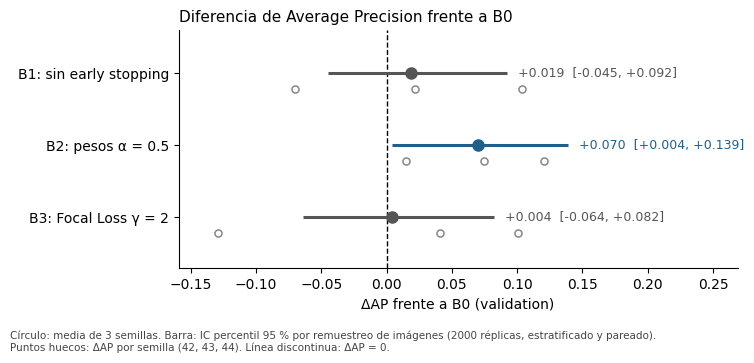

In [7]:
colors = {"B1": "#555555", "B2": "#1f5f8b", "B3": "#555555"}
fig, ax = plt.subplots(figsize=(7.5, 3.6))
ypos = np.arange(len(COMPARED))[::-1]

for y_i, c, config in zip(ypos, range(len(COMPARED)), COMPARED):
    ax.plot([ci_low[c], ci_high[c]], [y_i, y_i], color=colors[config], lw=2.2, solid_capstyle="butt", zorder=2)
    ax.plot(delta_mean[c], y_i, "o", color=colors[config], ms=8, zorder=3)
    ax.scatter(DELTA_SEED[c], np.full(len(SEEDS), y_i - 0.22), s=26, facecolors="white", edgecolors="#888888", lw=1.1, zorder=3)
    ax.annotate(f"{delta_mean[c]:+.3f}  [{ci_low[c]:+.3f}, {ci_high[c]:+.3f}]", (ci_high[c], y_i), xytext=(8, 0), textcoords="offset points", va="center", fontsize=9, color=colors[config])

ax.axvline(0, color="black", lw=1, ls="--", zorder=1)
ax.set_yticks(ypos)
ax.set_yticklabels(["B1: sin early stopping", "B2: pesos α = 0.5", "B3: Focal Loss γ = 2"])
ax.set_ylim(-0.7, len(COMPARED) - 0.4)
ax.set_xlim(min(ci_low.min(), DELTA_SEED.min()) - 0.03, ci_high.max() + 0.13)
ax.set_xlabel("ΔAP frente a B0 (validation)")
ax.set_title("Diferencia de Average Precision frente a B0", loc="left", fontsize=11)
for side in ("top", "right"):
    ax.spines[side].set_visible(False)

fig.text(
    0.01, 0.005,
    f"Círculo: media de 3 semillas. Barra: IC percentil {CI_LEVEL} % por remuestreo de imágenes ({N_BOOT} réplicas, estratificado y pareado).\n"
    "Puntos huecos: ΔAP por semilla (42, 43, 44). Línea discontinua: ΔAP = 0.",
    fontsize=7.5, color="#444444", va="bottom",
)
fig.tight_layout(rect=(0, 0.08, 1, 1))
fig.savefig(OUT_DIR / "delta_ap_vs_b0.png", dpi=200)
plt.show()

## 8. Interpretación provisional

**Lectura de los resultados (provisional).**

- **B2 (pesos α = 0.5)** tiene el ΔAP medio más alto (+0.070) y fue positivo en las tres semillas. Su intervalo por remuestreo de imágenes, [+0.004, +0.139], queda apenas por encima de cero: el límite inferior está muy cerca de 0, por lo que el resultado es compatible con una mejora modesta, y también con una casi nula.
- **B1 (sin early stopping)** y **B3 (Focal Loss)** tienen ΔAP medios pequeños (+0.019 y +0.004) con intervalos que incluyen el cero. Sus efectos por semilla cambian de signo (B1: −0.070 a +0.104; B3: −0.129 a +0.101). Con estos datos no se distingue su efecto de la variabilidad.
- Las dos fuentes de incertidumbre se leen por separado. La **variabilidad entre semillas** (sección 4) se basa solo en 3 repeticiones, por lo que su desviación estándar es una estimación muy imprecisa. El **intervalo bootstrap** (sección 5) mide el efecto de qué imágenes componen validation, con los modelos entrenados fijos; no incluye la variabilidad de entrenamiento. No se combinan en un solo intervalo.

**Salvedades.**

1. El IC bootstrap de B2 frente a B0 está **condicionado a la selección previa de configuraciones y checkpoints realizada sobre este mismo validation**: el checkpoint de cada corrida se eligió por `val_roc_auc` en validation y B2 se conservó tras compararse allí con B1 y B3. Por ello el intervalo no es una prueba confirmatoria independiente ni una evaluación final; describe la incertidumbre por muestreo de imágenes dado lo ya seleccionado, y no corrige la selección, con probable sesgo favorable a B2.
2. Los intervalos son de 95 % **por comparación** y no se corrigen por haber comparado tres experimentos ni por la selección posterior; que el de B2 excluya el cero no debe leerse como una prueba de significancia.
3. Solo hay 22 imágenes positivas operacionales (categorías originales 6 y 7 agrupadas): el AP depende en gran medida de cómo se ordenan unas pocas imágenes, y el bootstrap no puede representar patrones ausentes de la muestra. No hay identificadores de paciente, así que no se descarta dependencia entre imágenes, lo que haría los intervalos demasiado estrechos.
4. La fracción de réplicas con ΔAP > 0 es descriptiva y no es un valor p.
5. Una confirmación requiere datos no usados en la selección (por ejemplo, el conjunto de test en la evaluación final, o validación cruzada) y, de ser posible, más semillas.